In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/dataset-senti/Compressed/test_labels.pt
/kaggle/input/dataset-senti/Compressed/train_labels.pt
/kaggle/input/dataset-senti/Compressed/train_input_ids.pt
/kaggle/input/dataset-senti/Compressed/test_input_ids.pt
/kaggle/input/dataset-senti/Compressed/val_lengths.pt
/kaggle/input/dataset-senti/Compressed/val_input_ids.pt
/kaggle/input/dataset-senti/Compressed/train_lengths.pt
/kaggle/input/dataset-senti/Compressed/val_idx.npy
/kaggle/input/dataset-senti/Compressed/train_idx.npy
/kaggle/input/dataset-senti/Compressed/test_idx.npy
/kaggle/input/dataset-senti/Compressed/test_lengths.pt
/kaggle/input/dataset-senti/Compressed/val_labels.pt


In [2]:
import torch
import os
from torch.utils.data import Dataset, DataLoader
import numpy as np

In [3]:
torch.manual_seed(42)

In [4]:
# Set device (GPU if available, else CPU)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

Using device: cuda


In [5]:
# Define paths to preprocessed data
DATA_DIR = "/kaggle/input/dataset-senti/Compressed"

In [6]:
# Load preprocessed tensors
train_input_ids = torch.load(os.path.join(DATA_DIR, "train_input_ids.pt"))
val_input_ids = torch.load(os.path.join(DATA_DIR, "val_input_ids.pt"))
test_input_ids = torch.load(os.path.join(DATA_DIR, "test_input_ids.pt"))

train_lengths = torch.load(os.path.join(DATA_DIR, "train_lengths.pt"))
val_lengths = torch.load(os.path.join(DATA_DIR, "val_lengths.pt"))
test_lengths = torch.load(os.path.join(DATA_DIR, "test_lengths.pt"))

train_labels = torch.load(os.path.join(DATA_DIR, "train_labels.pt"))
val_labels = torch.load(os.path.join(DATA_DIR, "val_labels.pt"))
test_labels = torch.load(os.path.join(DATA_DIR, "test_labels.pt"))

print(f"Loaded training samples: {len(train_labels)}")
print(f"Loaded validation samples: {len(val_labels)}")
print(f"Loaded test samples: {len(test_labels)}")

Loaded training samples: 1400000
Loaded validation samples: 300000
Loaded test samples: 300000


In [7]:
# Global training configuration
CONFIG = {
    "BATCH_SIZE": 128,
    "EPOCHS": 20,
    "LEARNING_RATE": 1e-3,
    "MAX_SEQ_LENGTH": 170,
    "DEVICE": DEVICE
}

print("Setup complete.")

Setup complete.


In [8]:
# Cell 2: Define PyTorch Dataset and DataLoader for biLSTM
class SentimentDataset(torch.utils.data.Dataset):
    def __init__(self, input_ids, labels, lengths):
        self.input_ids = input_ids
        self.labels = labels
        self.lengths = lengths

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return {
            "input_ids": self.input_ids[idx],
            "label": self.labels[idx],
            "length": self.lengths[idx]
        }

# Create dataset instances
train_dataset = SentimentDataset(train_input_ids, train_labels, train_lengths)
val_dataset = SentimentDataset(val_input_ids, val_labels, val_lengths)
test_dataset = SentimentDataset(test_input_ids, test_labels, test_lengths)

# DataLoader creation
train_loader = DataLoader(train_dataset, batch_size=CONFIG["BATCH_SIZE"], shuffle=True,pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=CONFIG["BATCH_SIZE"], shuffle=False, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=CONFIG["BATCH_SIZE"], shuffle=False, pin_memory=True)

In [9]:
# Print a sample batch to verify shapes and contents
sample_batch = next(iter(train_loader))
print("Sample batch keys:", sample_batch.keys())
print("input_ids shape:", sample_batch["input_ids"].shape)
print("labels shape:", sample_batch["label"].shape)
print("lengths shape:", sample_batch["length"].shape)

Sample batch keys: dict_keys(['input_ids', 'label', 'length'])
input_ids shape: torch.Size([128, 170])
labels shape: torch.Size([128])
lengths shape: torch.Size([128])


In [10]:
import torch
import torch.nn as nn

class BiLSTMSentimentClassifier(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim=64,
        lstm_hidden_dim=64,
        dense_hidden_dim=64,
        dropout_rate=0.3,
        padding_idx=0
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=padding_idx
        )

        self.bilstm1 = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=lstm_hidden_dim,
            batch_first=True,
            bidirectional=True
        )

        self.bilstm2 = nn.LSTM(
            input_size=lstm_hidden_dim * 2,
            hidden_size=lstm_hidden_dim,
            batch_first=True,
            bidirectional=True
        )

        self.dropout = nn.Dropout(dropout_rate)
        self.fc1 = nn.Linear(lstm_hidden_dim * 2, dense_hidden_dim)
        self.batchnorm = nn.BatchNorm1d(dense_hidden_dim)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(dense_hidden_dim, 1)

    def forward(self, input_ids, lengths):
        embedded = self.embedding(input_ids)

        packed = nn.utils.rnn.pack_padded_sequence(
            embedded, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        out1, _ = self.bilstm1(packed)
        out1_unpacked, _ = nn.utils.rnn.pad_packed_sequence(out1, batch_first=True)

        packed = nn.utils.rnn.pack_padded_sequence(
            out1_unpacked, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        _, (hidden_n, _) = self.bilstm2(packed)

        # Concatenate last forward and backward hidden states
        hidden = torch.cat((hidden_n[-2], hidden_n[-1]), dim=1)  # (B, H*2)

        x = self.dropout(hidden)
        x = self.fc1(x)
        x = self.batchnorm(x)
        x = self.relu(x)
        x = self.dropout(x)
        logits = self.fc2(x)
        return logits


In [11]:
VOCAB_SIZE = 20000
EMBEDDING_DIM = 64
LSTM_HIDDEN_DIM = 64
DENSE_HIDDEN_DIM = 64
DROPOUT_RATE = 0.3
PAD_TOKEN_ID = 0  

In [13]:
import torch
import torch.nn as nn
import torch.nn.utils.prune as prune
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report
import copy
import time

# Assuming DEVICE, CONFIG, train_loader, val_loader, test_loader, and BiLSTMSentimentClassifier
# are already defined as in the original notebook

# Load the saved model
model = BiLSTMSentimentClassifier(
    vocab_size=VOCAB_SIZE,
    embedding_dim=EMBEDDING_DIM,
    lstm_hidden_dim=LSTM_HIDDEN_DIM,
    dense_hidden_dim=DENSE_HIDDEN_DIM,
    dropout_rate=DROPOUT_RATE,
    padding_idx=PAD_TOKEN_ID
).to(CONFIG["DEVICE"])
model.load_state_dict(torch.load("/kaggle/input/base_model/pytorch/default/1/best_bilstm_model.pt"))
print("Loaded saved model.")

# Binary accuracy function (from original notebook)
def binary_accuracy(preds, y):
    """
    Computes accuracy for binary predictions.
    preds: raw logits from the model
    y: ground truth labels (float tensor, 0 or 1)
    """
    probs = torch.sigmoid(preds)
    rounded = torch.round(probs)
    correct = (rounded == y).float()
    acc = correct.sum() / len(correct)
    return acc

# Function to apply unstructured pruning to specified layers
def apply_pruning(model, pruning_rate=0.2):
    # Define parameters to prune (exclude embedding and final fc2 layer)
    parameters_to_prune = [
        (model.bilstm1, 'weight_ih_l0'),  # Input-hidden weights of first LSTM
        (model.bilstm1, 'weight_hh_l0'),  # Hidden-hidden weights of first LSTM
        (model.bilstm2, 'weight_ih_l0'),  # Input-hidden weights of second LSTM
        (model.bilstm2, 'weight_hh_l0'),  # Hidden-hidden weights of second LSTM
        (model.fc1, 'weight'),            # First fully connected layer weights
    ]
    
    for module, param_name in parameters_to_prune:
        prune.l1_unstructured(module, name=param_name, amount=pruning_rate)
        # Remove the pruning mask to make pruning permanent
        prune.remove(module, param_name)
    
    # Flatten LSTM parameters to avoid memory warning
    model.bilstm1.flatten_parameters()
    model.bilstm2.flatten_parameters()
    
    print(f"Applied {pruning_rate*100}% pruning to LSTM and fc1 layers.")

# Function to count non-zero parameters
def count_nonzero_params(model):
    total_params = 0
    nonzero_params = 0
    for param in model.parameters():
        total_params += param.numel()
        nonzero_params += torch.count_nonzero(param).item()
    return nonzero_params, total_params

# Training and evaluation functions (reusing from original notebook)
def train_epoch(model, loader, optimizer, criterion, device):
    model.train()
    epoch_loss = 0
    epoch_acc = 0
    for batch in loader:
        input_ids = batch["input_ids"].to(device)
        labels = batch["label"].to(device).float()
        lengths = batch["length"].to(device)
        optimizer.zero_grad()
        logits = model(input_ids, lengths).squeeze(1)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        acc = binary_accuracy(logits, labels)
        epoch_loss += loss.item() * len(labels)
        epoch_acc += acc.item() * len(labels)
    return epoch_loss / len(loader.dataset), epoch_acc / len(loader.dataset)

def eval_epoch(model, loader, criterion, device):
    model.eval()
    epoch_loss = 0
    epoch_acc = 0
    all_preds = []
    all_targets = []
    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(device)
            labels = batch["label"].to(device).float()
            lengths = batch["length"].to(device)
            logits = model(input_ids, lengths).squeeze(1)
            loss = criterion(logits, labels)
            acc = binary_accuracy(logits, labels)
            epoch_loss += loss.item() * len(labels)
            epoch_acc += acc.item() * len(labels)
            # Collect predictions for metrics
            probs = torch.sigmoid(logits)
            preds = torch.round(probs).cpu().numpy()
            all_preds.extend(preds)
            all_targets.extend(labels.cpu().numpy())
    return epoch_loss / len(loader.dataset), epoch_acc / len(loader.dataset), all_preds, all_targets

# Iterative pruning and retraining
NUM_PRUNING_ITERATIONS = 5
PRUNING_RATE = 0.2  # Prune 20% of weights per iteration
RETRAIN_EPOCHS = 5   # Number of epochs to retrain after each pruning
PATIENCE = 3        # Early stopping patience
criterion = nn.BCEWithLogitsLoss().to(CONFIG["DEVICE"])

# Store initial weights for LTH
initial_state_dict = copy.deepcopy(model.state_dict())

# Pruning loop
best_val_loss = float('inf')
epochs_no_improve = 0
train_losses, val_losses = [], []
train_accs, val_accs = [], []

for iteration in range(NUM_PRUNING_ITERATIONS):
    print(f"\nPruning Iteration {iteration + 1}/{NUM_PRUNING_ITERATIONS}")
    
    # Apply pruning
    apply_pruning(model, pruning_rate=PRUNING_RATE)
    
    # Count parameters
    nonzero_params, total_params = count_nonzero_params(model)
    print(f"Non-zero parameters: {nonzero_params}/{total_params} ({nonzero_params/total_params*100:.2f}%)")
    
    # Reset optimizer
    optimizer = torch.optim.Adam(model.parameters(), lr=CONFIG["LEARNING_RATE"], weight_decay=1e-5)
    
    # Retrain
    for epoch in range(RETRAIN_EPOCHS):
        start_time = time.time()
        train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion, CONFIG["DEVICE"])
        val_loss, val_acc, _, _ = eval_epoch(model, val_loader, criterion, CONFIG["DEVICE"])
        train_losses.append(train_loss)
        val_accs.append(val_acc)
        elapsed = time.time() - start_time
        
        print(f"  Epoch {epoch+1}/{RETRAIN_EPOCHS} | "
              f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc*100:.2f}% | "
              f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc*100:.2f}% | "
              f"Time: {elapsed:.1f}s")
        
        # Early stopping
        if val_loss < best_val_loss - 1e-4:
            best_val_loss = val_loss
            epochs_no_improve = 0
            torch.save(model.state_dict(), f"/kaggle/working/pruned_bilstm_model_iter{iteration+1}.pt")
            print("    (Best pruned model saved)")
        else:
            epochs_no_improve += 1
            print(f"    (No improvement for {epochs_no_improve} epoch(s))")
            if epochs_no_improve >= PATIENCE:
                print(f"    Early stopping triggered after {epoch+1} epochs.")
                break
    
    # Reset early stopping for next iteration
    epochs_no_improve = 0
    best_val_loss = float('inf')

# Load the best pruned model (from the last iteration)
model.load_state_dict(torch.load(f"/kaggle/working/pruned_bilstm_model_iter{NUM_PRUNING_ITERATIONS}.pt"))
print(f"\nLoaded best pruned model from iteration {NUM_PRUNING_ITERATIONS}.")

# Evaluate on test set
test_loss, test_acc, all_preds, all_targets = eval_epoch(model, test_loader, criterion, CONFIG["DEVICE"])
print(f"\nTest Results for Pruned Model:")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc*100:.2f}%")
print(f"Test Precision: {precision_score(all_targets, all_preds):.4f}")
print(f"Test Recall: {recall_score(all_targets, all_preds):.4f}")
print(f"Test F1 Score: {f1_score(all_targets, all_preds):.4f}")
print("\nClassification Report:\n", classification_report(all_targets, all_preds, target_names=["Negative", "Positive"]))

# Save training stats
np.save("/kaggle/working/pruned_train_losses.npy", np.array(train_losses))
np.save("/kaggle/working/pruned_val_losses.npy", np.array(val_losses))
np.save("/kaggle/working/pruned_train_accs.npy", np.array(train_accs))
np.save("/kaggle/working/pruned_val_accs.npy", np.array(val_accs))

# Optional: Reset model to initial weights with the final mask (LTH winning ticket)
model.load_state_dict(initial_state_dict)
apply_pruning(model, pruning_rate=(1 - (1 - PRUNING_RATE) ** NUM_PRUNING_ITERATIONS))  # Cumulative pruning rate
torch.save(model.state_dict(), "/kaggle/working/winning_ticket_model.pt")
print("Saved winning ticket model with initial weights and final pruning mask.")

Loaded saved model.

Pruning Iteration 1/5
Applied 20.0% pruning to LSTM and fc1 layers.
Non-zero parameters: 1436250/1454337 (98.76%)
  Epoch 1/5 | Train Loss: 0.1241 | Train Acc: 95.48% | Val Loss: 0.1359 | Val Acc: 94.87% | Time: 489.8s
    (Best pruned model saved)
  Epoch 2/5 | Train Loss: 0.1185 | Train Acc: 95.69% | Val Loss: 0.1334 | Val Acc: 95.01% | Time: 483.2s
    (Best pruned model saved)
  Epoch 3/5 | Train Loss: 0.1152 | Train Acc: 95.84% | Val Loss: 0.1355 | Val Acc: 95.00% | Time: 496.3s
    (No improvement for 1 epoch(s))
  Epoch 4/5 | Train Loss: 0.1128 | Train Acc: 95.97% | Val Loss: 0.1342 | Val Acc: 94.98% | Time: 485.8s
    (No improvement for 2 epoch(s))
  Epoch 5/5 | Train Loss: 0.1104 | Train Acc: 96.04% | Val Loss: 0.1393 | Val Acc: 94.91% | Time: 482.4s
    (No improvement for 3 epoch(s))
    Early stopping triggered after 5 epochs.

Pruning Iteration 2/5
Applied 20.0% pruning to LSTM and fc1 layers.
Non-zero parameters: 1436250/1454337 (98.76%)
  Epoch 1/5 

In [14]:
# Function to calculate pruned weights in specified layers
def calculate_pruned_weights(model, layers_to_prune, initial_state_dict=None):
    """
    Calculate the total number and percentage of weights pruned in specified layers.
    
    Args:
        model: PyTorch model (e.g., BiLSTMSentimentClassifier) after pruning.
        layers_to_prune: List of tuples (module_name, param_name) for layers to check.
        initial_state_dict: Optional state_dict of the model before pruning (default: None).
                           If None, assumes all initial weights were non-zero.
    
    Returns:
        dict: Contains total_weights, nonzero_weights, weights_pruned, percent_pruned.
    """
    total_weights = 0
    nonzero_weights = 0
    
    for module_name, param_name in layers_to_prune:
        module = getattr(model, module_name)
        param = getattr(module, param_name)
        total_weights += param.numel()
        nonzero_weights += torch.count_nonzero(param).item()
    
    # Calculate pruned weights
    if initial_state_dict is not None:
        initial_nonzero = 0
        for module_name, param_name in layers_to_prune:
            module_weights = initial_state_dict[f"{module_name}.{param_name}"]
            initial_nonzero += torch.count_nonzero(module_weights).item()
        weights_pruned = initial_nonzero - nonzero_weights
        percent_pruned = (weights_pruned / initial_nonzero) * 100 if initial_nonzero > 0 else 0
    else:
        weights_pruned = total_weights - nonzero_weights
        percent_pruned = (weights_pruned / total_weights) * 100 if total_weights > 0 else 0
    
    return {
        "total_weights": total_weights,
        "nonzero_weights": nonzero_weights,
        "weights_pruned": weights_pruned,
        "percent_pruned": percent_pruned
    }

In [18]:
 # Define layers to prune
layers_to_prune = [
        ('bilstm1', 'weight_ih_l0'),
        ('bilstm1', 'weight_hh_l0'),
        ('bilstm2', 'weight_ih_l0'),
        ('bilstm2', 'weight_hh_l0'),
        ('fc1', 'weight'),
    ]

In [19]:
# Before pruning loop
initial_stats = calculate_pruned_weights(model, layers_to_prune, initial_state_dict)
print(f"Before pruning: {initial_stats['weights_pruned']}/{initial_stats['total_weights']} "
      f"({initial_stats['percent_pruned']:.2f}%)")

# Inside pruning loop, after apply_pruning
stats = calculate_pruned_weights(model, layers_to_prune, initial_state_dict)
print(f"After iteration {iteration + 1}: {stats['weights_pruned']}/{stats['total_weights']} "
      f"({stats['percent_pruned']:.2f}%)")

Before pruning: 60584/90112 (67.23%)
After iteration 5: 60584/90112 (67.23%)


In [26]:
import numpy as np

# Load saved training and validation stats
train_losses = np.load("/kaggle/working/pruned_train_losses.npy")
val_losses = np.load("/kaggle/working/pruned_val_losses.npy")
train_accs = np.load("/kaggle/working/pruned_train_accs.npy")
val_accs = np.load("/kaggle/working/pruned_val_accs.npy")

# Generate epoch numbers (1 to number of epochs)
epochs = list(range(1, len(train_losses) + 1))

# Print loaded data for verification
print(f"Loaded {len(train_losses)} epochs")
print(f"Train Losses: {train_losses}")
print(f"Val Losses: {val_losses}")
print(f"Train Accuracies: {train_accs}")
print(f"Val Accuracies: {val_accs}")

Loaded 22 epochs
Train Losses: [0.12409689 0.11853417 0.11521833 0.11282649 0.1103622  0.11427763
 0.10858294 0.1055508  0.10350525 0.1017306  0.10729726 0.10116981
 0.0986295  0.09676456 0.10322672 0.09637976 0.09409056 0.09258823
 0.10011176 0.09258092 0.09036991 0.08892107]
Val Losses: []
Train Accuracies: []
Val Accuracies: [0.94867667 0.95008333 0.95004333 0.94981    0.94914667 0.94939667
 0.94782    0.94965333 0.94782333 0.94912667 0.94936333 0.94926667
 0.94935333 0.94826667 0.94949333 0.9487     0.94764667 0.94696
 0.94857333 0.94772    0.94681667 0.94673   ]


ValueError: x and y must have same first dimension, but have shapes (22,) and (0,)

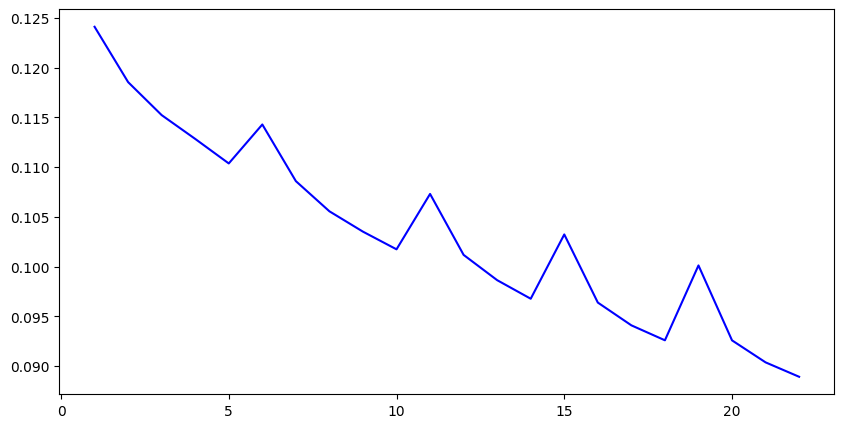

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(epochs, train_losses, label="Training Loss", color="blue")
plt.plot(epochs, val_losses, label="Validation Loss", color="red")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss vs. Epoch")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(epochs, train_accs, label="Training Accuracy", color="blue")
plt.plot(epochs, val_accs, label="Validation Accuracy", color="red")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Accuracy vs. Epoch")
plt.legend()
plt.grid(True)
plt.show()

ValueError: x and y must have same first dimension, but have shapes (22,) and (0,)

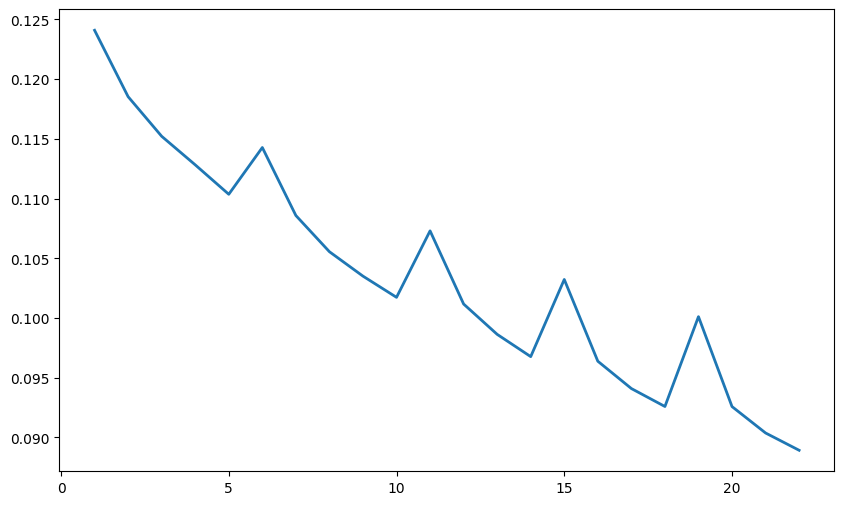

In [21]:
import os
import matplotlib.pyplot as plt
import numpy as np


# Create epochs array based on the number of epochs completed
epochs = np.arange(1, len(train_losses) + 1)

# Plot Loss
plt.figure(figsize=(10,6))
plt.plot(epochs, train_losses, label='Train Loss', linewidth=2)
plt.plot(epochs, val_losses, label='Validation Loss', linewidth=2)
plt.xlabel('Epoch', fontsize=14)
plt.ylabel('Loss', fontsize=14)
plt.title('Training and Validation Loss', fontsize=16)
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('/kaggle/working/loss_plot.png', dpi=300, bbox_inches='tight')
plt.show()

# Plot Accuracy
plt.figure(figsize=(10,6))
plt.plot(epochs, train_accs, label='Train Accuracy', linewidth=2)
plt.plot(epochs, val_accs, label='Validation Accuracy', linewidth=2)
plt.xlabel('Epoch', fontsize=14)
plt.ylabel('Accuracy', fontsize=14)
plt.title('Training and Validation Accuracy', fontsize=16)
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('/kaggle/working/accuracy_plot.png', dpi=300, bbox_inches='tight')
plt.show()
